<a href="https://colab.research.google.com/github/kevin4965-hue/ARTIFEX/blob/main/EA3_B_RNN_NAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EA3 · Opción B: anticipar anomalías en métricas de servicios con una RNN

**Énfasis II — Principios de Deep Learning y Redes Neuronales** · Ingeniería de Software y Datos
**Evidencia:** EA3. Implementación básica de una red neuronal · **Caso:** NubeAndina (empresa ficticia)
**Familia sugerida en EA2:** red recurrente (LSTM o GRU) · **Dataset:** Numenta Anomaly Benchmark (NAB), carpeta realAWSCloudwatch

| Estudiante | Modalidad |
| --- | --- |
| José Quevin Ordóñez | Entrega individual |

## Cómo usar este notebook

Este notebook es un **punto de partida**, no una solución. Ya trae la descarga del dataset, una exploración mínima, las particiones y las funciones de evaluación, para que la pareja dedique su tiempo a lo que evalúa la EA3: **implementar, entrenar, evaluar y exportar el modelo que propuso en el Reto 6 de la EA2**.

1. Ábrelo en Google Colab (*Archivo → Guardar una copia en Drive*) o en un entorno local con TensorFlow 2.16 o superior.
2. Ejecuta las celdas en orden. Las celdas marcadas con **`TODO`** son las que deben completar; las celdas marcadas con **`DECISIÓN`** traen un valor por defecto que pueden cambiar si lo justifican en el informe.
3. No cambien los nombres `modelo`, `historial`, `x_train_prep`, `x_val_prep`, `x_test_prep`, `y_train`, `y_val`, `y_test` ni `construir_modelo()`: la EA4 partirá de este mismo notebook para optimizar el modelo.
4. Entreguen el notebook **ejecutado, con todas sus salidas visibles**.

> **¿Prefieren PyTorch?** Conserven las secciones 1 a 5 (datos, particiones, preprocesamiento y línea base) y reemplacen las secciones 6 a 9 por su equivalente en PyTorch (`nn.Module`, `DataLoader`, ciclo de entrenamiento y `torch.save(model.state_dict(), ...)`). Las funciones de evaluación usan arreglos de NumPy y sirven para ambos *frameworks*. Mantengan las mismas particiones y métricas.

La guía de la actividad (PDF) explica los seis retos. Cada sección del notebook indica a qué reto corresponde; las preguntas marcadas como **Para el informe** se responden en el PDF, no aquí.

## 1. Entorno y reproducibilidad (Reto 1)

Se fija una semilla y se registran las versiones. Copien estas versiones en el informe.

In [1]:
# Sección 1 · Entorno y reproducibilidad (Reto 1)
import json, os, random, re, sys, time, urllib.request, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
import sklearn
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score,
                             precision_score, recall_score)

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)  # fija las semillas de Python, NumPy y TensorFlow
# tf.config.experimental.enable_op_determinism()  # opcional: más reproducible, pero más lento

print('Python      ', sys.version.split()[0])
print('TensorFlow  ', tf.__version__)
print('Keras       ', keras.__version__)
print('scikit-learn', sklearn.__version__)
print('GPU         ', tf.config.list_physical_devices('GPU') or 'no disponible (se usará la CPU)')

DATOS = Path('datos_ea3')
DATOS.mkdir(exist_ok=True)

def descargar(url, destino):
    """Descarga un archivo solo si aún no existe."""
    destino = Path(destino)
    if not destino.exists():
        print('Descargando', url)
        urllib.request.urlretrieve(url, destino)
    return destino

Python       3.13.16
TensorFlow   2.21.0
Keras        3.13.2
scikit-learn 1.6.1
GPU          [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Datos: descarga y exploración (Reto 1)

La carpeta `realAWSCloudwatch` de NAB tiene 17 archivos CSV. Cada uno contiene **una sola métrica** de AWS CloudWatch (CPU, red, disco, solicitudes al balanceador) medida cada 5 minutos, con las columnas `timestamp` y `value`. Las anomalías están en `labels/combined_windows.json` como **ventanas** de inicio y fin.

Tengan en cuenta que en NAB cada ventana es un **margen de tolerancia** alrededor de una anomalía etiquetada, no el instante exacto de la falla: cada ventana suma cerca del 10 % de los puntos de su serie.

**Licencia:** el código de NAB tiene licencia MIT; el repositorio no declara una licencia específica para los datos. Indíquenlo en el informe.

**DECISIÓN · `SERIES`:** por defecto se usan las 17 series. Pueden restringirse a un tipo de métrica (por ejemplo, solo CPU) si lo justifican.

In [2]:
BASE_NAB = 'https://raw.githubusercontent.com/numenta/NAB/master'
ARCHIVOS = [
    'ec2_cpu_utilization_24ae8d.csv',
    'ec2_cpu_utilization_53ea38.csv',
    'ec2_cpu_utilization_5f5533.csv',
    'ec2_cpu_utilization_77c1ca.csv',
    'ec2_cpu_utilization_825cc2.csv',
    'ec2_cpu_utilization_ac20cd.csv',
    'ec2_cpu_utilization_c6585a.csv',
    'ec2_cpu_utilization_fe7f93.csv',
    'ec2_disk_write_bytes_1ef3de.csv',
    'ec2_disk_write_bytes_c0d644.csv',
    'ec2_network_in_257a54.csv',
    'ec2_network_in_5abac7.csv',
    'elb_request_count_8c0756.csv',
    'grok_asg_anomaly.csv',
    'iio_us-east-1_i-a2eb1cd9_NetworkIn.csv',
    'rds_cpu_utilization_cc0c53.csv',
    'rds_cpu_utilization_e47b3b.csv',
]
SERIES = ARCHIVOS  # DECISIÓN: p. ej. [a for a in ARCHIVOS if 'cpu_utilization' in a]

descargar(f'{BASE_NAB}/labels/combined_windows.json', DATOS / 'combined_windows.json')
for nombre in SERIES:
    descargar(f'{BASE_NAB}/data/realAWSCloudwatch/{nombre}', DATOS / nombre)
with open(DATOS / 'combined_windows.json', encoding='utf-8') as f:
    VENTANAS_ANOMALAS = json.load(f)

def cargar_serie(nombre):
    df = pd.read_csv(DATOS / nombre, parse_dates=['timestamp'])
    df['anomalia'] = 0
    for inicio, fin in VENTANAS_ANOMALAS['realAWSCloudwatch/' + nombre]:
        dentro = (df['timestamp'] >= pd.Timestamp(inicio)) & (df['timestamp'] <= pd.Timestamp(fin))
        df.loc[dentro, 'anomalia'] = 1
    return df

series = {nombre: cargar_serie(nombre) for nombre in SERIES}
pd.DataFrame({
    'puntos': {n: len(df) for n, df in series.items()},
    'inicio': {n: df['timestamp'].min() for n, df in series.items()},
    'intervalo': {n: df['timestamp'].diff().median() for n, df in series.items()},
    '% en ventana anómala': {n: round(100 * df['anomalia'].mean(), 1) for n, df in series.items()},
})

Descargando https://raw.githubusercontent.com/numenta/NAB/master/labels/combined_windows.json
Descargando https://raw.githubusercontent.com/numenta/NAB/master/data/realAWSCloudwatch/ec2_cpu_utilization_24ae8d.csv
Descargando https://raw.githubusercontent.com/numenta/NAB/master/data/realAWSCloudwatch/ec2_cpu_utilization_53ea38.csv
Descargando https://raw.githubusercontent.com/numenta/NAB/master/data/realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv
Descargando https://raw.githubusercontent.com/numenta/NAB/master/data/realAWSCloudwatch/ec2_cpu_utilization_77c1ca.csv
Descargando https://raw.githubusercontent.com/numenta/NAB/master/data/realAWSCloudwatch/ec2_cpu_utilization_825cc2.csv
Descargando https://raw.githubusercontent.com/numenta/NAB/master/data/realAWSCloudwatch/ec2_cpu_utilization_ac20cd.csv
Descargando https://raw.githubusercontent.com/numenta/NAB/master/data/realAWSCloudwatch/ec2_cpu_utilization_c6585a.csv
Descargando https://raw.githubusercontent.com/numenta/NAB/master/data/rea

,puntos,inicio,intervalo,% en ventana anómala
ec2_cpu_utilization_24ae8d.csv,4032,2014-02-14 14:30:00,0 days 00:05:00,10.0
ec2_cpu_utilization_53ea38.csv,4032,2014-02-14 14:30:00,0 days 00:05:00,10.0
ec2_cpu_utilization_5f5533.csv,4032,2014-02-14 14:27:00,0 days 00:05:00,10.0
ec2_cpu_utilization_77c1ca.csv,4032,2014-04-02 14:25:00,0 days 00:05:00,10.0
ec2_cpu_utilization_825cc2.csv,4032,2014-04-10 00:04:00,0 days 00:05:00,8.5
ec2_cpu_utilization_ac20cd.csv,4032,2014-04-02 14:29:00,0 days 00:05:00,10.0
ec2_cpu_utilization_c6585a.csv,4032,2014-04-02 14:29:00,0 days 00:05:00,0.0
ec2_cpu_utilization_fe7f93.csv,4032,2014-02-14 14:27:00,0 days 00:05:00,10.0
ec2_disk_write_bytes_1ef3de.csv,4730,2014-03-01 17:34:00,0 days 00:05:00,10.0
ec2_disk_write_bytes_c0d644.csv,4032,2014-04-02 14:25:00,0 days 00:05:00,10.0


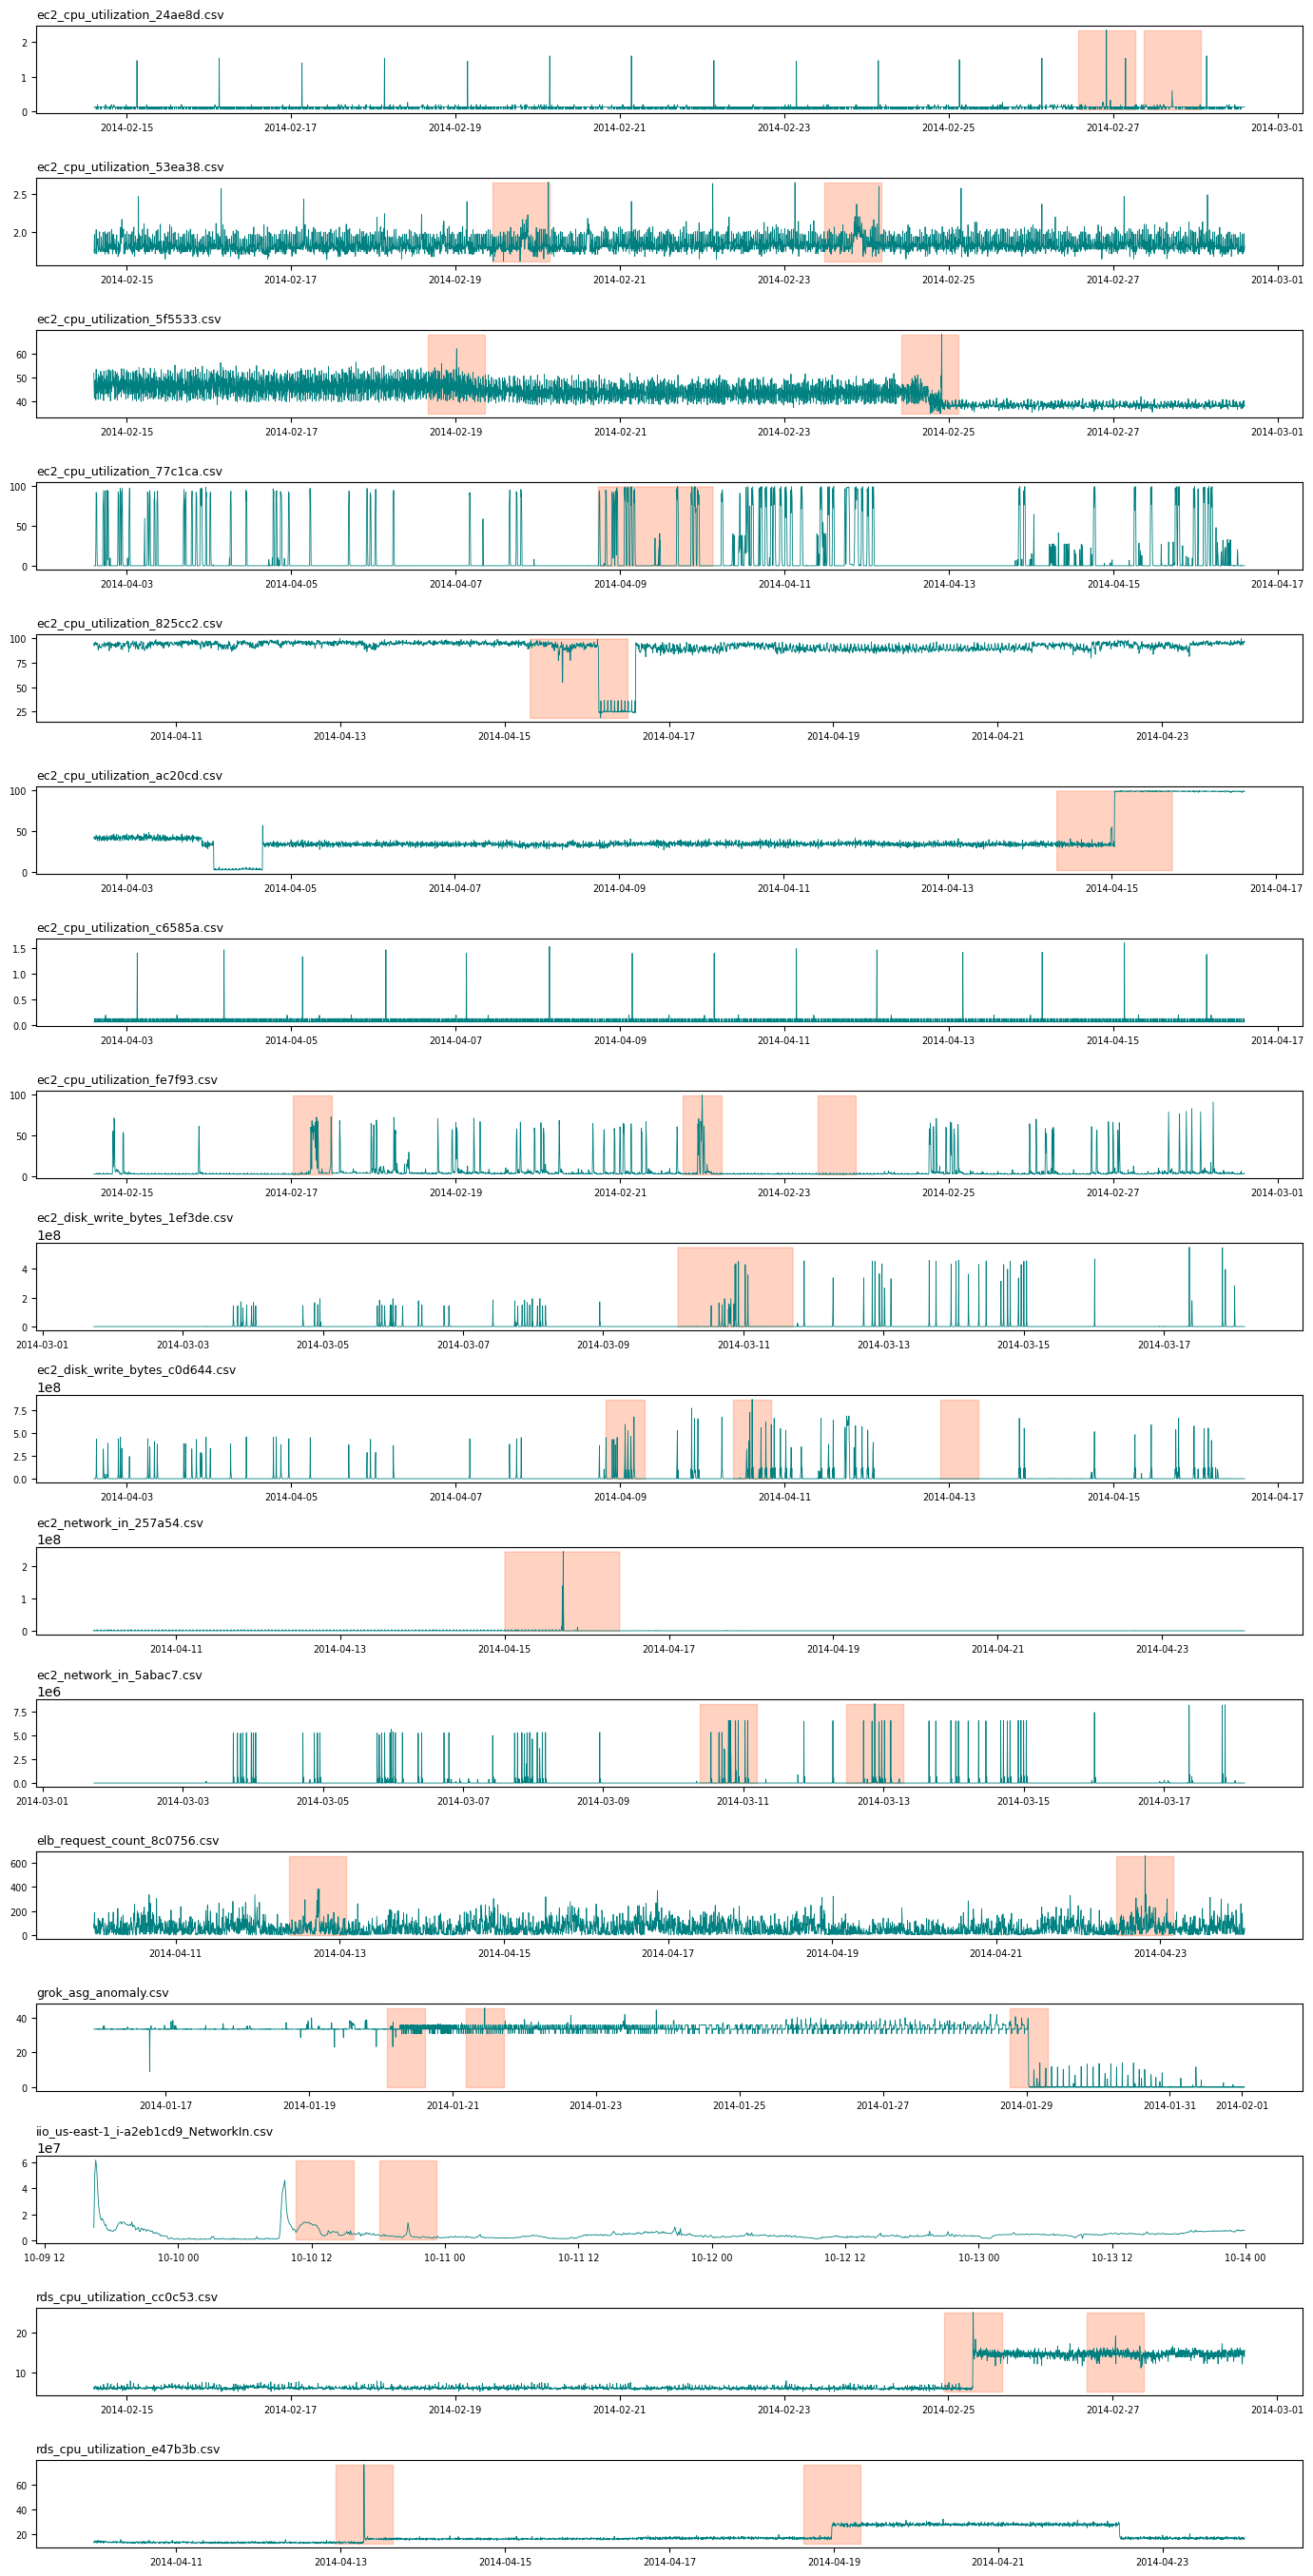

In [3]:
n = len(series)
fig, ejes = plt.subplots(n, 1, figsize=(14, 1.6 * n), sharex=False)
for eje, (nombre, df) in zip(np.atleast_1d(ejes), series.items()):
    eje.plot(df['timestamp'], df['value'], lw=.6, color='teal')
    eje.fill_between(df['timestamp'], df['value'].min(), df['value'].max(),
                     where=df['anomalia'] == 1, color='coral', alpha=.35, step='mid')
    eje.set_title(nombre, fontsize=9, loc='left'); eje.tick_params(labelsize=7)
plt.tight_layout(); plt.savefig('fig_series_nab.png', dpi=110); plt.show()

**Para el informe (Reto 1):** ¿qué patrones (ciclos diarios, picos, cambios de nivel) se ven en las series? ¿Qué diferencias tendrían estas métricas frente a las de la API de NubeAndina?

## 3. Particiones cronológicas y ventanas (Reto 2)

En series temporales **no** se mezclan los ejemplos al azar: el modelo no puede aprender del futuro para predecir el pasado. Cada serie se corta en el tiempo: el primer 70 % es entrenamiento, el siguiente 15 % es validación y el último 15 % es prueba. Las ventanas se construyen **dentro** de cada tramo, sin cruzar los cortes.

Cada ejemplo es una **ventana** de `VENTANA` mediciones consecutivas. La etiqueta depende de lo que la pareja haya definido en la EA2:

- `MODO_ETIQUETA = 'anticipa'`: `y = 1` si alguna de las `HORIZONTE` mediciones **siguientes** cae dentro de una ventana anómala.
- `MODO_ETIQUETA = 'dentro'`: `y = 1` si la **última** medición de la ventana está dentro de una ventana anómala.

**DECISIÓN:** `VENTANA = 48` equivale a 4 horas y `HORIZONTE = 6` a 30 minutos. Justifiquen sus valores.

In [4]:
VENTANA = 36            # DECISIÓN: 36 × 5 min = 3 h, la longitud propuesta en el Reto 6 de la EA2
HORIZONTE = 12          # DECISIÓN: 12 × 5 min = 1 h, el margen de anticipación definido en la EA2
MODO_ETIQUETA = 'anticipa'  # DECISIÓN: 'anticipa' o 'dentro'
CORTES = (0.70, 0.85)   # fin de entrenamiento y fin de validación, en fracción del tiempo

def ventanas_de_tramo(valores, anomalia):
    x, y = [], []
    for i in range(len(valores) - VENTANA - HORIZONTE + 1):
        x.append(valores[i:i + VENTANA])
        if MODO_ETIQUETA == 'anticipa':
            y.append(anomalia[i + VENTANA:i + VENTANA + HORIZONTE].max())
        else:
            y.append(anomalia[i + VENTANA - 1])
    return np.array(x, dtype='float32'), np.array(y, dtype='int32')

ESCALADO = {}   # media y desviación de cada serie, calculadas SOLO con su tramo de entrenamiento
particiones = {'entrenamiento': ([], []), 'validación': ([], []), 'prueba': ([], [])}
for nombre, df in series.items():
    valores, anomalia = df['value'].to_numpy('float32'), df['anomalia'].to_numpy()
    c1, c2 = int(CORTES[0] * len(df)), int(CORTES[1] * len(df))
    media, desv = float(valores[:c1].mean()), float(valores[:c1].std() + 1e-8)
    ESCALADO[nombre] = {'media': media, 'desv': desv}
    for clave, (ini, fin) in zip(particiones, [(0, c1), (c1, c2), (c2, len(df))]):
        xs, ys = ventanas_de_tramo((valores[ini:fin] - media) / desv, anomalia[ini:fin])
        particiones[clave][0].append(xs); particiones[clave][1].append(ys)

# Forma que espera una capa recurrente: (ejemplos, pasos de tiempo, variables por paso)
(x_train_prep, y_train), (x_val_prep, y_val), (x_test_prep, y_test) = [
    (np.concatenate(xs)[..., np.newaxis], np.concatenate(ys)) for xs, ys in particiones.values()]

pd.DataFrame({'ventanas': [len(y_train), len(y_val), len(y_test)],
              'positivas': [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
              '% positivas': [round(100 * y.mean(), 1) for y in (y_train, y_val, y_test)]},
             index=list(particiones))

,ventanas,positivas,% positivas
entrenamiento,46613,4616,9.9
validación,9363,750,8.0
prueba,9367,1135,12.1


## 4. Preprocesamiento mínimo (Reto 2)

El preprocesamiento ya quedó aplicado en la celda anterior:

- **Escalado por serie** (puntaje z): a cada medición se le resta la media y se divide por la desviación de **su** serie, calculadas solo con el tramo de entrenamiento. Así, CPU en porcentaje y bytes de red quedan en escalas comparables, y la validación y la prueba no influyen en el preprocesamiento.
- **Ventaneo:** cada ejemplo tiene forma `(VENTANA, 1)`: `VENTANA` pasos de tiempo con una variable por paso.

**DECISIÓN · pesos por clase:** las ventanas positivas son minoría. Con `USAR_PESOS_CLASE = True` la pérdida da más peso a los errores en la clase positiva.

**Para el informe (Reto 2):** ¿por qué sería un error calcular la media y la desviación con toda la serie? ¿Por qué no se pueden barajar las ventanas antes de dividir?

In [5]:
USAR_PESOS_CLASE = True  # DECISIÓN
proporcion_positiva = y_train.mean()
pesos_clase = {0: 0.5 / (1 - proporcion_positiva), 1: 0.5 / proporcion_positiva}
print('Formas:', x_train_prep.shape, x_val_prep.shape, x_test_prep.shape)
print('Pesos por clase:', {k: round(v, 2) for k, v in pesos_clase.items()})

Formas: (46613, 36, 1) (9363, 36, 1) (9367, 36, 1)
Pesos por clase: {0: np.float64(0.55), 1: np.float64(5.05)}


## 5. Línea base sin deep learning (Retos 3 y 4)

En detección de anomalías la exactitud engaña: un modelo que **nunca** alerta acierta en cerca del 90 % de las ventanas. Por eso se reportan la **precisión**, la **sensibilidad** (*recall*), la **F1** de la clase positiva y el **área bajo la curva precisión-sensibilidad** (AP).

El umbral de decisión se elige en **validación** (el que maximiza la F1) y luego se aplica sin cambios en prueba. Se calculan dos líneas base:

- **Regla de umbral:** alerta si el valor absoluto del puntaje z de la última medición supera `k`.
- **Regresión logística** sobre la ventana aplanada.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve

def elegir_umbral(y_real, puntaje):
    """Umbral que maximiza la F1 de la clase positiva (usar solo con validación)."""
    precision, sensibilidad, umbrales = precision_recall_curve(y_real, puntaje)
    f1 = 2 * precision * sensibilidad / np.clip(precision + sensibilidad, 1e-8, None)
    return float(umbrales[np.argmax(f1[:-1])])

def evaluar_binaria(y_real, puntaje, umbral, titulo=''):
    y_pred = (puntaje >= umbral).astype(int)
    metricas = {'precision': float(precision_score(y_real, y_pred, zero_division=0)),
                'sensibilidad': float(recall_score(y_real, y_pred, zero_division=0)),
                'f1': float(f1_score(y_real, y_pred, zero_division=0)),
                'ap': float(average_precision_score(y_real, puntaje)),
                'umbral': float(umbral)}
    if titulo:
        print(f'--- {titulo} ---', {k: round(v, 3) for k, v in metricas.items()})
    return metricas

# Regla de umbral sobre |z| de la última medición
puntaje_regla_val = np.abs(x_val_prep[:, -1, 0])
umbral_regla = elegir_umbral(y_val, puntaje_regla_val)
evaluar_binaria(y_val, puntaje_regla_val, umbral_regla, 'Regla |z| · validación')

# Regresión logística sobre la ventana aplanada
base_logistica = LogisticRegression(max_iter=2000, class_weight='balanced')
base_logistica.fit(x_train_prep[..., 0], y_train)
puntaje_base_val = base_logistica.predict_proba(x_val_prep[..., 0])[:, 1]
umbral_base = elegir_umbral(y_val, puntaje_base_val)
metricas_base_val = evaluar_binaria(y_val, puntaje_base_val, umbral_base, 'Regresión logística · validación')

--- Regla |z| · validación --- {'precision': 0.353, 'sensibilidad': 0.235, 'f1': 0.282, 'ap': 0.19, 'umbral': 14.677}
--- Regresión logística · validación --- {'precision': 0.294, 'sensibilidad': 0.131, 'f1': 0.181, 'ap': 0.131, 'umbral': 0.711}


## 6. Implementación del modelo (Reto 3)

Recuerden la estructura de una red recurrente para clasificar secuencias: una o más capas `LSTM` o `GRU` que recorren la ventana paso a paso y conservan un estado oculto, la salida del último paso, y una capa `Dense(1, activation='sigmoid')` que entrega la probabilidad de anomalía.

Completen `construir_modelo()` con la arquitectura **del Reto 6 de su EA2**. Si necesitan cambiarla (por ejemplo, porque la forma de la entrada resultó distinta), documenten el cambio y su razón en el informe.

La función recibe `config` para que la EA4 pueda crear modelos nuevos con otros hiperparámetros. En esta evidencia **no** se hace búsqueda de hiperparámetros: elijan valores razonables, justifíquenlos y entrenen.

In [7]:
CONFIG_BASE = {'learning_rate': 1e-3, 'batch_size': 64, 'epocas': 30}  # DECISIÓN: justifiquen cada valor

def construir_modelo(config=CONFIG_BASE):
    """Construye y compila la RNN del Reto 6 de la EA2."""
    entradas = keras.Input(shape=(VENTANA, 1), name='ventana')
    # Arquitectura del Reto 6 de la EA2: Conv1D + LSTM + densa
    x = layers.Conv1D(config.get('filtros', 16), kernel_size=config.get('kernel', 5), padding='same',
                      activation='relu', name='conv1d_patrones_locales')(entradas)   # (36, 1) -> (36, 16)
    x = layers.LSTM(config.get('unidades_lstm', 32), name='lstm_secuencia')(x)        # (36, 16) -> (32)
    x = layers.Dropout(config.get('dropout', 0.2), name='dropout')(x)                 # (32) -> (32)
    x = layers.Dense(16, activation='relu', name='densa')(x)                          # (32) -> (16)
    salidas = layers.Dense(1, activation='sigmoid', name='prob_anomalia')(x)          # (16) -> (1)

    modelo = keras.Model(entradas, salidas, name='rnn_ea3')
    modelo.compile(optimizer=keras.optimizers.Adam(config['learning_rate']),
                   loss='binary_crossentropy',
                   metrics=[keras.metrics.AUC(curve='PR', name='ap'), keras.metrics.Recall(name='sensibilidad')])
    return modelo

modelo = construir_modelo()
modelo.summary()

Model: "rnn_ea3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ventana (InputLayer)            │ (None, 36, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_patrones_locales         │ (None, 36, 16)         │            96 │
│ (Conv1D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_secuencia (LSTM)           │ (None, 32)             │         6,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prob_anomalia (Dense)           │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,913 (27.00 KB)

 Trainable params: 6,913 (27.00 KB)

 Non-trainable params: 0 (0.00 B)

**Para el informe (Reto 3):** expliquen qué representa un paso de tiempo en su modelo, qué guarda el estado oculto y cómo cambia la forma del tensor de capa en capa.

## 7. Entrenamiento (Reto 4)

Se entrena con el conjunto de entrenamiento y se vigila el de validación. `EarlyStopping` detiene el entrenamiento cuando la pérdida de validación deja de mejorar. Las ventanas se barajan **dentro** del entrenamiento (`shuffle=True`), lo que no rompe el orden temporal, porque cada ventana conserva su secuencia interna y las particiones ya están separadas en el tiempo.

In [8]:
def graficar_curvas(historial, metrica):
    """Curvas de pérdida y de una métrica en entrenamiento y validación."""
    h = historial.history
    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
    for eje, clave in zip(ejes, ['loss', metrica]):
        if clave in h:
            eje.plot(h[clave], marker='o', label='entrenamiento')
            eje.plot(h['val_' + clave], marker='o', label='validación')
        eje.set_title(clave); eje.set_xlabel('época'); eje.legend(); eje.grid(alpha=.3)
    plt.tight_layout(); plt.savefig('fig_curvas_ea3.png', dpi=130); plt.show()

Epoch 1/30
729/729 - 14s - 20ms/step - ap: 0.2120 - loss: 0.6556 - sensibilidad: 0.3941 - val_ap: 0.1820 - val_loss: 0.9759 - val_sensibilidad: 0.6827
Epoch 2/30
729/729 - 6s - 8ms/step - ap: 0.2577 - loss: 0.6235 - sensibilidad: 0.5962 - val_ap: 0.1908 - val_loss: 0.9266 - val_sensibilidad: 0.6613
Epoch 3/30
729/729 - 7s - 10ms/step - ap: 0.2918 - loss: 0.5806 - sensibilidad: 0.7000 - val_ap: 0.1645 - val_loss: 0.9335 - val_sensibilidad: 0.6960
Epoch 4/30
729/729 - 6s - 8ms/step - ap: 0.3308 - loss: 0.5444 - sensibilidad: 0.7875 - val_ap: 0.1526 - val_loss: 1.0113 - val_sensibilidad: 0.6307
Epoch 5/30
729/729 - 7s - 10ms/step - ap: 0.3544 - loss: 0.5237 - sensibilidad: 0.8928 - val_ap: 0.1617 - val_loss: 1.0125 - val_sensibilidad: 0.6680
Epoch 6/30
729/729 - 6s - 8ms/step - ap: 0.3716 - loss: 0.5147 - sensibilidad: 0.8912 - val_ap: 0.1569 - val_loss: 1.0409 - val_sensibilidad: 0.6187
Epoch 7/30
729/729 - 7s - 10ms/step - ap: 0.3675 - loss: 0.4992 - sensibilidad: 0.9170 - val_ap: 0.150

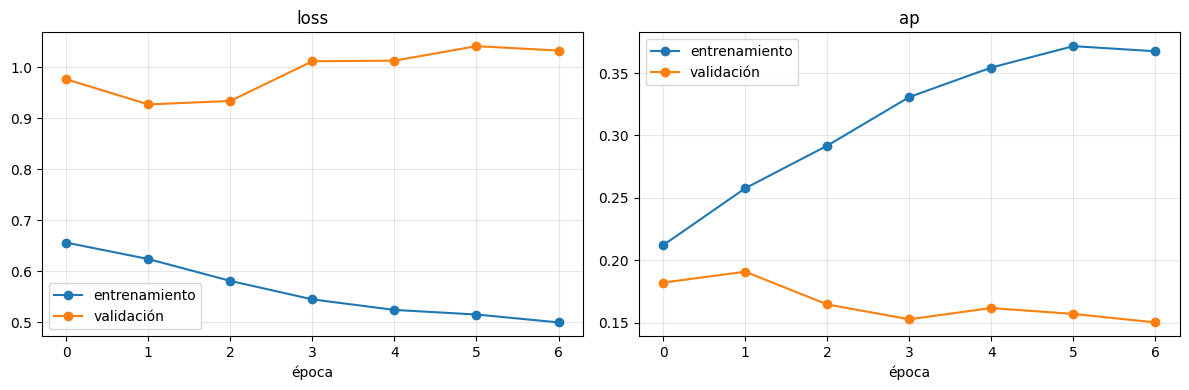

In [9]:
callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)]

inicio = time.time()
historial = modelo.fit(
    x_train_prep, y_train,
    validation_data=(x_val_prep, y_val),
    epochs=CONFIG_BASE['epocas'], batch_size=CONFIG_BASE['batch_size'], shuffle=True,
    class_weight=pesos_clase if USAR_PESOS_CLASE else None,
    callbacks=callbacks, verbose=2)
tiempo_entrenamiento = time.time() - inicio
print(f'Entrenamiento: {tiempo_entrenamiento:.0f} s · épocas: {len(historial.history["loss"])}')

graficar_curvas(historial, 'ap')

## 8. Evaluación (Reto 4)

El umbral del modelo se elige en **validación**. Después se evalúa **una sola vez** en prueba con ese umbral fijo.

In [10]:
puntaje_val = modelo.predict(x_val_prep, verbose=0).ravel()
UMBRAL = elegir_umbral(y_val, puntaje_val)
metricas_modelo_val = evaluar_binaria(y_val, puntaje_val, UMBRAL, 'Modelo · validación')
print('Línea base · validación:', {k: round(v, 3) for k, v in metricas_base_val.items()})

--- Modelo · validación --- {'precision': 0.341, 'sensibilidad': 0.231, 'f1': 0.275, 'ap': 0.199, 'umbral': 0.933}
Línea base · validación: {'precision': 0.294, 'sensibilidad': 0.131, 'f1': 0.181, 'ap': 0.131, 'umbral': 0.711}


--- Modelo · prueba --- {'precision': 0.248, 'sensibilidad': 0.359, 'f1': 0.293, 'ap': 0.139, 'umbral': 0.933}
--- Regresión logística · prueba --- {'precision': 0.402, 'sensibilidad': 0.35, 'f1': 0.374, 'ap': 0.307, 'umbral': 0.711}


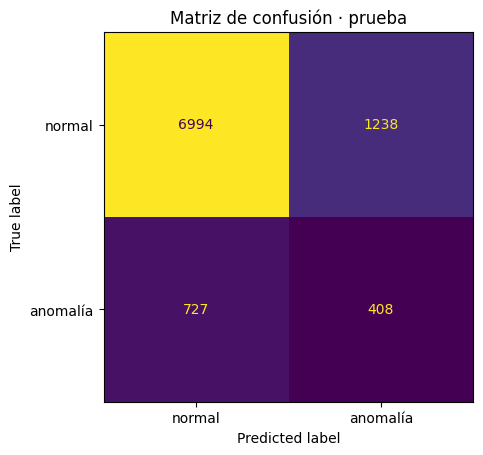

In [11]:
# Evaluación final en prueba: ejecútenla una sola vez, con el umbral elegido en validación.
puntaje_test = modelo.predict(x_test_prep, verbose=0).ravel()
metricas_modelo_test = evaluar_binaria(y_test, puntaje_test, UMBRAL, 'Modelo · prueba')
metricas_base_test = evaluar_binaria(y_test, base_logistica.predict_proba(x_test_prep[..., 0])[:, 1],
                                     umbral_base, 'Regresión logística · prueba')

ConfusionMatrixDisplay(confusion_matrix(y_test, (puntaje_test >= UMBRAL).astype(int)),
                       display_labels=['normal', 'anomalía']).plot(colorbar=False)
plt.title('Matriz de confusión · prueba'); plt.savefig('fig_confusion_ea3.png', dpi=130, bbox_inches='tight'); plt.show()

## 9. Despliegue como prototipo (Reto 5)

Un modelo desplegado no es solo un archivo de pesos: también necesita **el mismo preprocesamiento** que se usó al entrenarlo. Por eso se guardan juntos el modelo y los artefactos que lo acompañan.

1. Se guarda el modelo en formato `.keras` (con PyTorch: `torch.save(model.state_dict(), 'modelo_ea3.pth')`).
2. Se carga **de nuevo** desde el archivo y se comprueba que produce las mismas predicciones que el modelo en memoria.
3. La función `predecir()` recibe un ejemplo **en bruto**, aplica el preprocesamiento y devuelve la estimación que vería una persona de NubeAndina.

**Para el informe:** ¿cómo se integraría `predecir()` en los sistemas de NubeAndina (API, microservicio, tarea programada)? ¿Qué se monitorearía después de desplegarlo? ¿En qué momento interviene la revisión humana?

In [12]:
RUTA_MODELO = 'modelo_ea3_rnn.keras'
modelo.save(RUTA_MODELO)
with open('artefactos_ea3.json', 'w', encoding='utf-8') as f:
    json.dump({'ventana': VENTANA, 'horizonte': HORIZONTE, 'modo_etiqueta': MODO_ETIQUETA,
               'umbral': UMBRAL, 'escalado': ESCALADO}, f, ensure_ascii=False, indent=2)

modelo_cargado = keras.models.load_model(RUTA_MODELO)
iguales = np.allclose(modelo.predict(x_test_prep[:64], verbose=0),
                      modelo_cargado.predict(x_test_prep[:64], verbose=0), atol=1e-5)
print('¿El modelo cargado predice lo mismo que el original?', iguales)

def predecir(valores_recientes, serie):
    """Recibe las últimas VENTANA mediciones en bruto de una serie y devuelve la alerta."""
    valores = np.asarray(valores_recientes, dtype='float32')[-VENTANA:]
    if len(valores) < VENTANA:
        raise ValueError(f'Se necesitan al menos {VENTANA} mediciones')
    esc = ESCALADO[serie]
    x = ((valores - esc['media']) / esc['desv']).reshape(1, VENTANA, 1)
    prob = float(modelo_cargado.predict(x, verbose=0)[0, 0])
    return {'probabilidad': round(prob, 3), 'alerta': prob >= UMBRAL, 'umbral': round(UMBRAL, 3)}

serie_ejemplo = SERIES[0]
ultimas = series[serie_ejemplo]['value'].to_numpy()[-VENTANA:]
print('Serie:', serie_ejemplo, '→', predecir(ultimas, serie_ejemplo))

¿El modelo cargado predice lo mismo que el original? True
Serie: ec2_cpu_utilization_24ae8d.csv → {'probabilidad': 0.131, 'alerta': False, 'umbral': 0.933}


### Reto 5c · Ejemplos nuevos en bruto

Dos tramos de CPU **inventados** (no salen del dataset) para la instancia `ec2_cpu_utilization_5f5533.csv`, cuyo nivel habitual ronda el 45 %: uno estable y uno con una subida sostenida en la última hora. Se pasan en bruto (porcentaje de CPU) a `predecir()`.

estable           · últimos valores [44.2 43.8 45.9 46.7] → {'probabilidad': 0.158, 'alerta': False, 'umbral': 0.933}
subida sostenida  · últimos valores [61.9 62.5 63.1 64.9] → {'probabilidad': 0.914, 'alerta': False, 'umbral': 0.933}


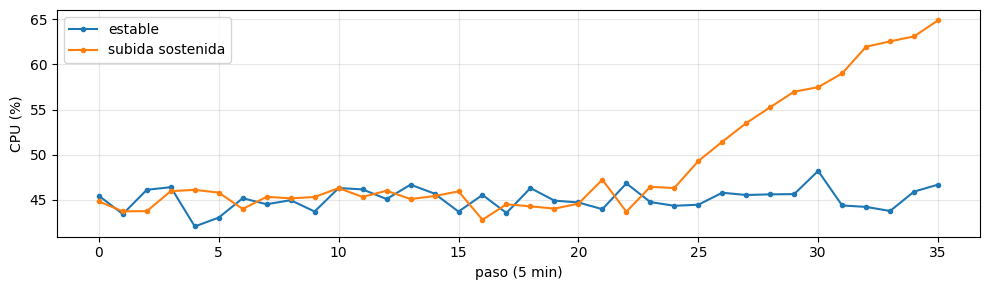

In [13]:
rng = np.random.default_rng(SEMILLA)
serie_nueva = 'ec2_cpu_utilization_5f5533.csv'
tramo_estable = 45 + rng.normal(0, 1.5, VENTANA)                     # 3 h alrededor del 45 %
tramo_subida = np.r_[45 + rng.normal(0, 1.5, VENTANA - 12),          # 2 h normales...
                     np.linspace(48, 66, 12) + rng.normal(0, 1.0, 12)] # ...y 1 h de subida hasta 66 %
for nombre_tramo, tramo in [('estable', tramo_estable), ('subida sostenida', tramo_subida)]:
    print(f'{nombre_tramo:17s} · últimos valores {np.round(tramo[-4:], 1)} →', predecir(tramo, serie_nueva))

fig, eje = plt.subplots(figsize=(10, 3))
eje.plot(tramo_estable, marker='.', label='estable'); eje.plot(tramo_subida, marker='.', label='subida sostenida')
eje.set_xlabel('paso (5 min)'); eje.set_ylabel('CPU (%)'); eje.legend(); eje.grid(alpha=.3)
plt.tight_layout(); plt.savefig('fig_ejemplos_nuevos.png', dpi=130); plt.show()

## 10. Registro de resultados (Retos 4 y 6)

La celda siguiente reúne la configuración y los resultados en `resultados_ea3.json`. Copien la tabla en el informe; **no reporten cifras que el notebook no haya producido**.

In [14]:
resultados = {
    'opcion': 'B',
    'framework': f'TensorFlow {tf.__version__} / Keras {keras.__version__}',
    'semilla': SEMILLA,
    'config': CONFIG_BASE,
    'tamanos_particiones': {'entrenamiento': int(len(y_train)), 'validacion': int(len(y_val)), 'prueba': int(len(y_test))},
    'epocas_entrenadas': len(historial.history['loss']),
    'tiempo_entrenamiento_s': round(tiempo_entrenamiento, 1),
    'parametros_modelo': int(modelo.count_params()),
    'linea_base_validacion': metricas_base_val,
    'modelo_validacion': metricas_modelo_val,
    'linea_base_prueba': metricas_base_test,
    'modelo_prueba': metricas_modelo_test,
}
with open('resultados_ea3.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False, default=float)

tabla = pd.DataFrame({
    'Línea base · validación': metricas_base_val,
    'Modelo · validación': metricas_modelo_val,
    'Línea base · prueba': metricas_base_test,
    'Modelo · prueba': metricas_modelo_test,
}).T.round(3)
tabla

,precision,sensibilidad,f1,ap,umbral
Línea base · validación,0.294,0.131,0.181,0.131,0.711
Modelo · validación,0.341,0.231,0.275,0.199,0.933
Línea base · prueba,0.402,0.350,0.374,0.307,0.711
Modelo · prueba,0.248,0.359,0.293,0.139,0.933


## 11. Para cerrar (Reto 6)

Respondan en el informe, apoyándose en los resultados anteriores:

- ¿Qué limitaciones del dataset (licencia, origen, etiquetas, desbalance, idioma, diferencia con los datos reales de NubeAndina) afectan la confianza en estos resultados?
- ¿Qué riesgos éticos o legales tendría usar este modelo con datos reales de la empresa (privacidad, sesgo, responsabilidad si falla)?
- ¿Qué tres cosas optimizarían en la EA4 (preprocesamiento, hiperparámetros, regularización) y qué evidencia de este notebook los lleva a pensarlo?